# **Proyecto 2: Procesamiento de imágenes y modelos de regresión con Python**
### **Primera parte**

**Alumnos:** Colombo Carolina - Eket Leandro  

##**Inciso 1. Leer y redimensionar una imagen**

In [1]:
from pathlib import Path
import sys

try:
    # Si estamos en Google Colab, montamos Drive y usamos la ruta de Drive
    from google.colab import drive
    drive.mount('/content/drive')
    base_dir = Path("/content/drive/MyDrive/Colab Notebooks/Proyecto2")
except ImportError:
    # Si estamos en local (VS Code / Jupyter), usamos la carpeta actual del proyecto
    base_dir = Path.cwd()
folder = str(base_dir / "Fotos originales")
resultados = str(base_dir / "Resultados")

# Nos aseguramos de que la carpeta Resultados exista y que Python encuentre fotoapp.py
Path(resultados).mkdir(parents=True, exist_ok=True)
if str(base_dir) not in sys.path:
    sys.path.append(str(base_dir))

Mounted at /content/drive


In [2]:
# importamos 'fotoapp.py'
from fotoapp import abrir_imagen, leer_y_redimensionar, ajustar_contraste_histograma, aplicar_filtro, detectar_bordes
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance
import cv2
import numpy as np

In [3]:
# definimos la ruta de la imagen
ruta = folder + "/ana-taylo-joy.jpg"
#ruta = folder + "/timothee-chalamet.jpg"
#ruta = folder + "/zendaya.jpg"
#ruta = folder + "/tom-holland.jpg"

Youtube (1280, 720)


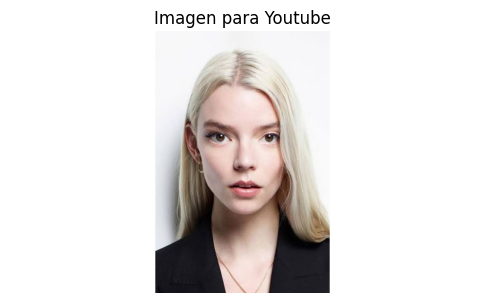

Instagram (1080, 1350)


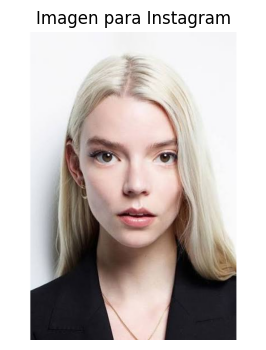

Twitter (1600, 900)


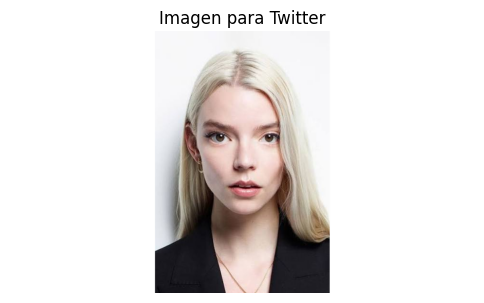

Facebook (1200, 630)


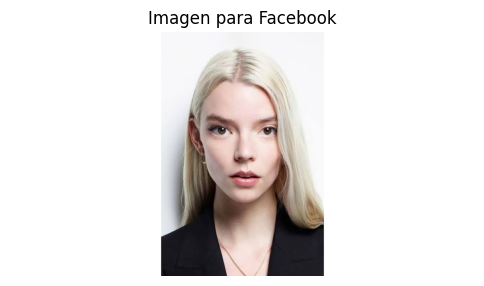

In [4]:
# Usamos la función con las cuatro plataformas
dimensiones = ["Youtube", "Instagram", "Twitter", "Facebook"]
for plataforma in dimensiones:
    nombre_archivo = f"redimensionada_{plataforma.lower()}.png"
    ruta_guardado = resultados + "/" + nombre_archivo

    resultado = leer_y_redimensionar(ruta, plataforma, ruta_guardado)

    print(plataforma, resultado.size)

    plt.figure(figsize=(6, 4))
    plt.imshow(resultado)
    plt.title(f"Imagen para {plataforma}")
    plt.axis("off")
    plt.show()

##**Inciso 2. Ajustar el contraste mediante el histograma**

In [5]:
# Abrimos la fotografía original
imagen_original = Image.open(ruta).convert("RGB")

# Creamos una versión más oscura
oscura = ImageEnhance.Brightness(imagen_original).enhance(0.3)
oscura.save(resultados + "/oscura.jpg")

# Creamos una versión con exceso de luz
sobreexpuesta = ImageEnhance.Brightness(imagen_original).enhance(2.0)
sobreexpuesta.save(resultados + "/sobreexpuesta.jpg")

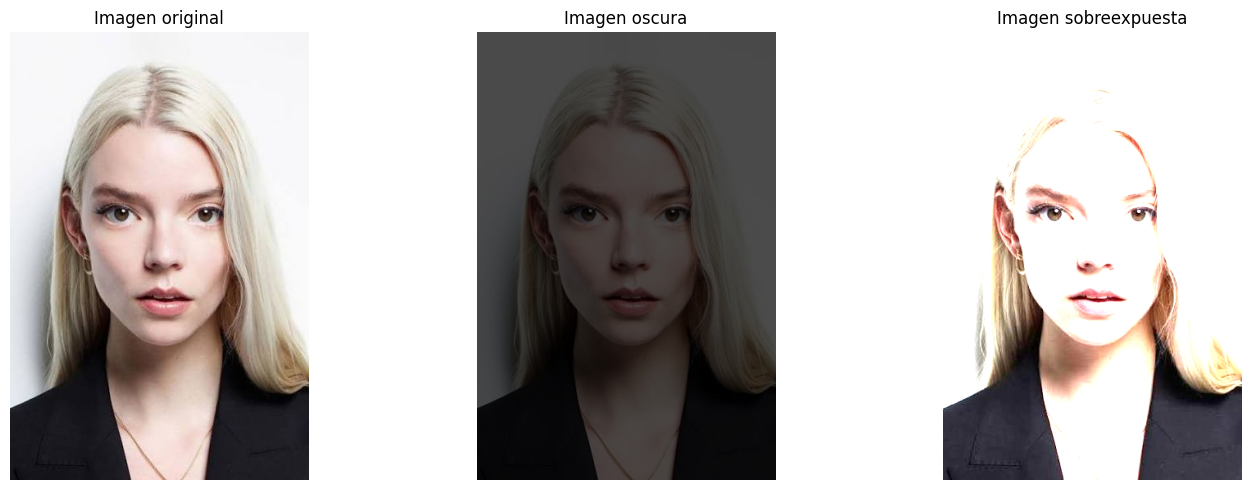

In [6]:
# Mostramos las tres imágenes para comparar
figura, ejes = plt.subplots(1, 3, figsize=(15, 5))

ejes[0].imshow(imagen_original)
ejes[0].set_title("Imagen original")

ejes[1].imshow(oscura)
ejes[1].set_title("Imagen oscura")

ejes[2].imshow(sobreexpuesta)
ejes[2].set_title("Imagen sobreexpuesta")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()

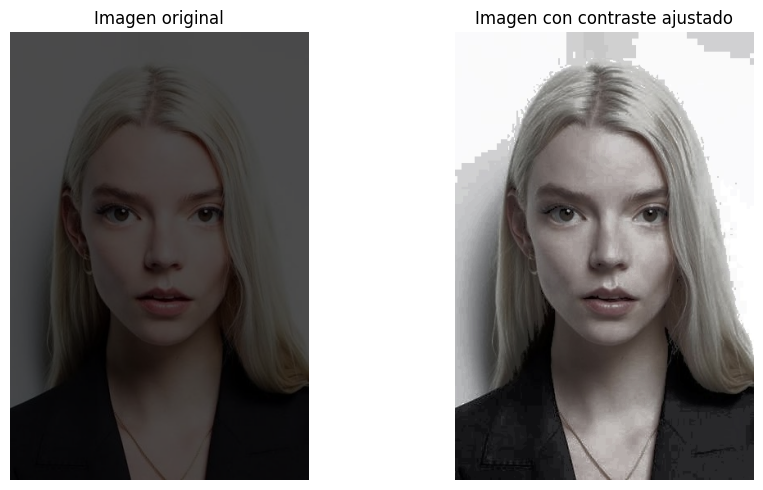

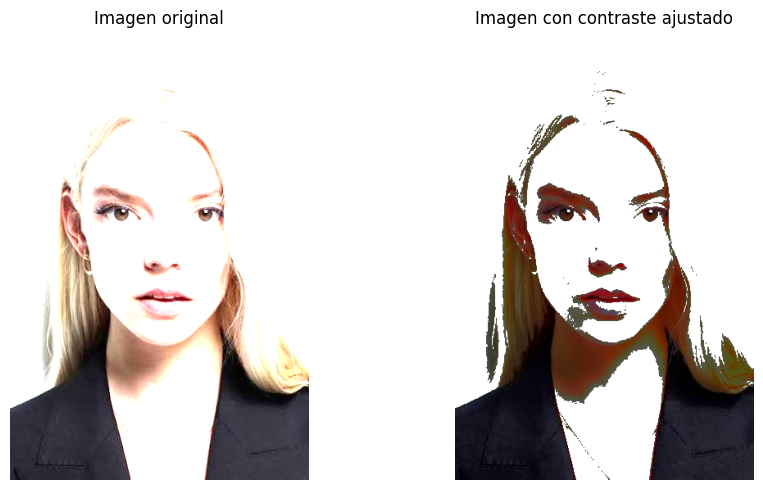

In [7]:
# Ecualizamos la imagen oscura
resultado_oscura = ajustar_contraste_histograma(oscura, resultados + "/contraste_oscura.png")

# Ecualizamos la imagen sobreexpuesta
resultado_sobreexpuesta = ajustar_contraste_histograma(sobreexpuesta, resultados + "/contraste_sobreexpuesta.png")

##**Inciso 3. Filtros**

In [8]:
imagen = Image.open(ruta).convert("RGB")
nombres_filtros = [
    "Blur",
    "Contour",
    "Detail",
    "Edge Enhance",
    "Edge Enhance More",
    "Emboss",
    "Find Edges",
    "Sharpen",
    "Smooth"]

for nombre in nombres_filtros:
    archivo = nombre.lower().replace(" ", "_")
    aplicar_filtro(
        imagen,
        nombre,
        resultados + "/filtro_" + archivo + ".png")

Output hidden; open in https://colab.research.google.com to view.

### Comparación de los 9 filtros de Pillow
- **Suavizado y enfoque:** `Blur` y `Smooth` reducen el ruido y suavizan detalles finos (`Blur` es más marcado), mientras que `Sharpen` y `Detail` realzan la nitidez y los detalles locales.
- **Realce de bordes:** `Edge Enhance` y `Edge Enhance More` acentúan los contornos manteniendo la imagen original de fondo (`Edge Enhance More` con mayor intensidad).
- **Efectos artísticos / extracción de contornos:** `Contour` y `Find Edges` destacan casi exclusivamente los bordes sobre fondo claro u oscuro respectivamente, y `Emboss` genera un efecto de relieve en escala de grises.

##**Inciso 4. Detección de bordes y contornos**

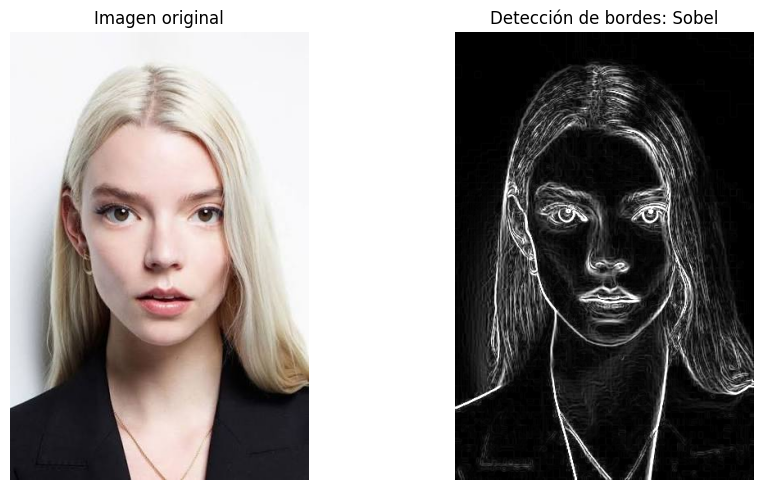

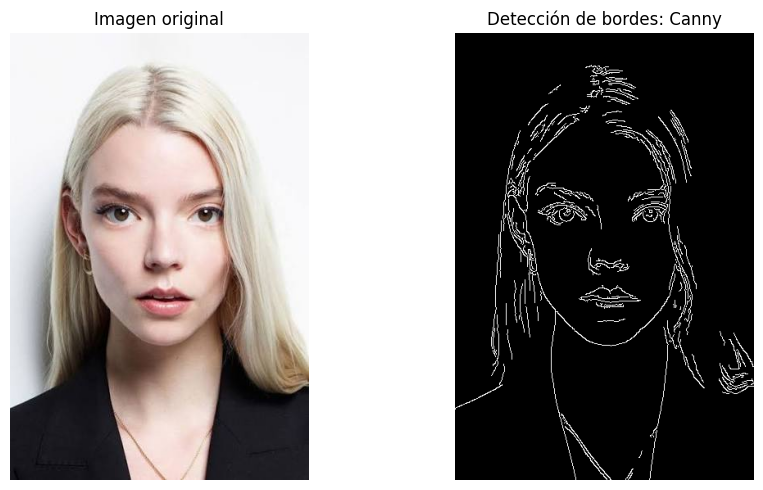

In [9]:
# Cargamos la imagen
imagen = Image.open(ruta).convert("RGB")

# Aplicamos Sobel y guardamos la comparación
resultado_sobel = detectar_bordes(imagen,"sobel",resultados + "/comparacion_sobel.png")

# Aplicamos Canny y guardamos la comparación
resultado_canny = detectar_bordes(imagen,"canny", resultados + "/comparacion_canny.png")

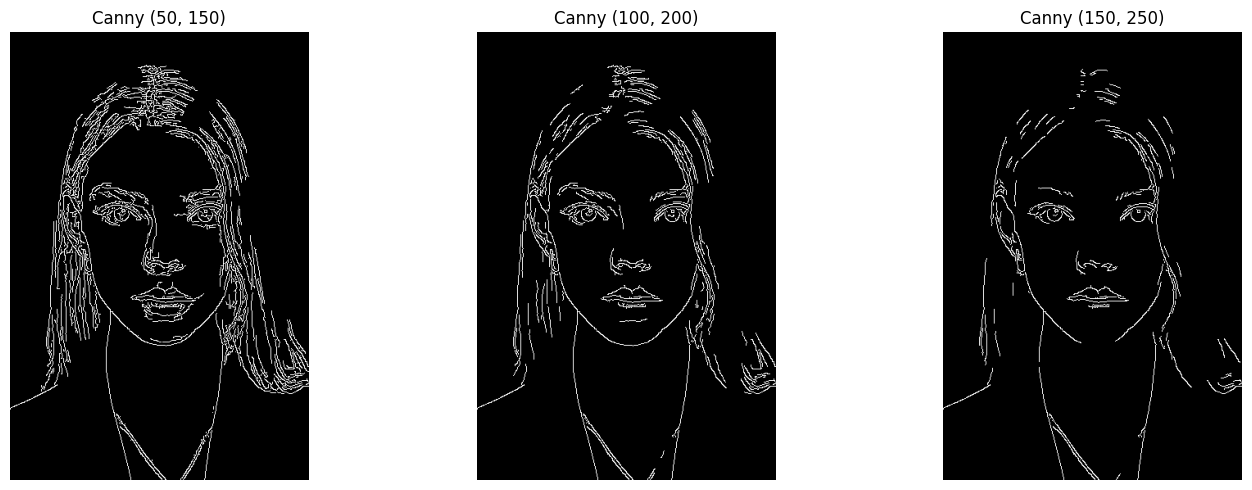

In [10]:
# Ajustamos y comparamos diferentes parámetros de Canny
gris = cv2.cvtColor(np.array(imagen), cv2.COLOR_RGB2GRAY)

canny_1 = cv2.Canny(gris, 50, 150)
canny_2 = cv2.Canny(gris, 100, 200)
canny_3 = cv2.Canny(gris, 150, 250)

figura, ejes = plt.subplots(1, 3, figsize=(15, 5))

ejes[0].imshow(canny_1, cmap="gray")
ejes[0].set_title("Canny (50, 150)")

ejes[1].imshow(canny_2, cmap="gray")
ejes[1].set_title("Canny (100, 200)")

ejes[2].imshow(canny_3, cmap="gray")
ejes[2].set_title("Canny (150, 250)")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
figura.savefig(
    resultados + "/prueba_parametros_canny.png",
    dpi=150,
    bbox_inches="tight")
plt.show()
plt.close(figura)

### Comparación de técnicas y parámetros
- **Sobel vs. Canny:** `Sobel` calcula la magnitud del gradiente en X e Y produciendo bordes continuos con distintos niveles de intensidad (escala de grises), mientras que `Canny` aplica supresión de no-máximos e histéresis para obtener contornos binarizados, finos y bien definidos tipo boceto.
- **Ajuste de umbrales en Canny:** Con `(50, 150)` aparecen más detalles finos y algo de ruido del fondo; con `(150, 250)` se pierden trazos suaves del rostro; el par `(100, 200)` logra el mejor equilibrio entre definición de rasgos y limpieza del fondo.

##**Inciso 5. Menú principal de la aplicación**


========== FOTOAPP ==========
1. Cargar y redimensionar imagen
2. Ajustar contraste
3. Aplicar filtro
4. Detectar bordes y contornos
5. Salir

Seleccione una opción: 1
Ingrese la ruta local o URL de la imagen: https://upload.wikimedia.org/wikipedia/commons/3/3d/Ana_de_Armas_by_Gage_Skidmore_2.jpg?utm_source=es.wikipedia.org&utm_campaign=index&utm_content=original
Ingrese la plataforma (YouTube, Instagram, Twitter o Facebook): youtube

Imagen cargada y redimensionada correctamente.
Guardada en: /content/drive/MyDrive/Colab Notebooks/Proyecto2/Resultados/redimensionada_youtube.png

========== FOTOAPP ==========
1. Cargar y redimensionar imagen
2. Ajustar contraste
3. Aplicar filtro
4. Detectar bordes y contornos
5. Salir

Seleccione una opción: 2


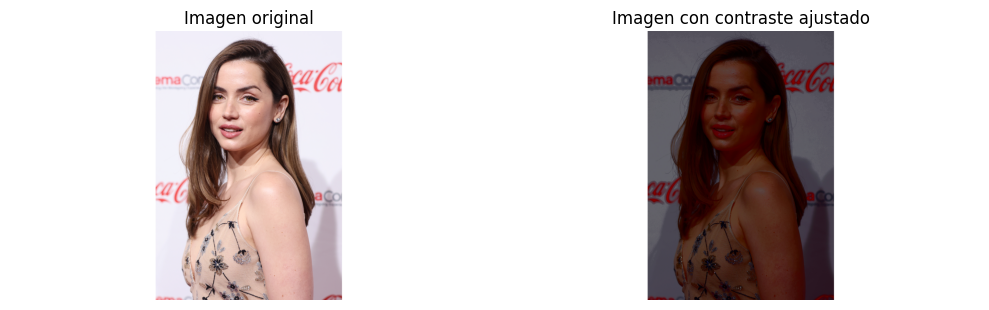


Comparación guardada en: /content/drive/MyDrive/Colab Notebooks/Proyecto2/Resultados/contraste_menu.png

========== FOTOAPP ==========
1. Cargar y redimensionar imagen
2. Ajustar contraste
3. Aplicar filtro
4. Detectar bordes y contornos
5. Salir

Seleccione una opción: 3

Filtros disponibles:
1. Blur
2. Contour
3. Detail
4. Edge Enhance
5. Edge Enhance More
6. Emboss
7. Find Edges
8. Sharpen
9. Smooth

Seleccione el número o nombre del filtro: blur


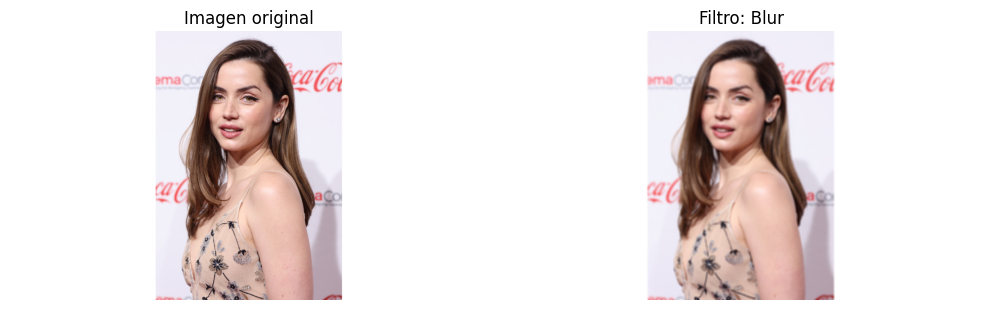


Comparación guardada en: /content/drive/MyDrive/Colab Notebooks/Proyecto2/Resultados/filtro_blur.png

========== FOTOAPP ==========
1. Cargar y redimensionar imagen
2. Ajustar contraste
3. Aplicar filtro
4. Detectar bordes y contornos
5. Salir

Seleccione una opción: 4
Ingrese la técnica (Sobel o Canny): canny


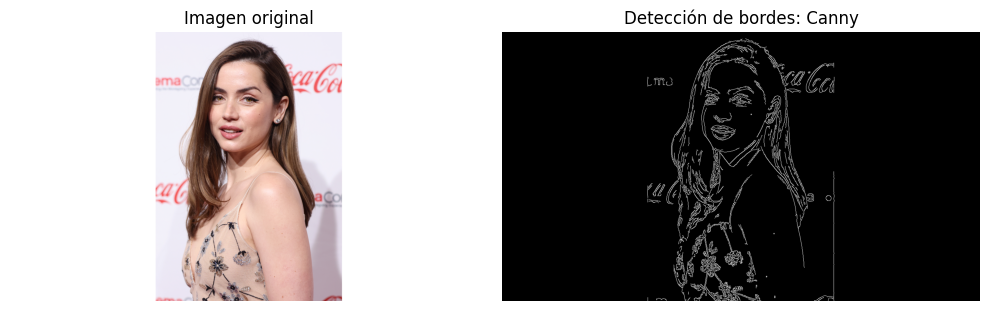


Comparación guardada en: /content/drive/MyDrive/Colab Notebooks/Proyecto2/Resultados/bordes_canny.png

========== FOTOAPP ==========
1. Cargar y redimensionar imagen
2. Ajustar contraste
3. Aplicar filtro
4. Detectar bordes y contornos
5. Salir

Seleccione una opción: 5

Gracias por utilizar FOTOAPP. ¡Hasta luego!


In [14]:
import importlib
import fotoapp

# Recargamos el archivo actualizado
importlib.reload(fotoapp)

# Ejecutamos el menú
fotoapp.main(resultados)